In [1]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub
kagglehub.login()
# KGAT_75a9dd51fa8adbf133da815aef6c0963

In [3]:
# Download latest version
path = kagglehub.competition_download('che-1147-2026')

print("Path to competition files:", path)

Path to competition files: /Users/helenliu/.cache/kagglehub/competitions/che-1147-2026


In [4]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import randint, uniform, loguniform

# ============================
# 1. Load data
# ============================

train = pd.read_csv(os.path.join(path, "train.csv"))
test = pd.read_csv(os.path.join(path, "test.csv"))

TARGET = "CO2 uptake at 0.15 bar and 298K"

# ============================
# 2. Select common features
# ============================

feature_cols = [
    col for col in test.columns
    if col != "MOFname" and col in train.columns
]

X = train[feature_cols].copy()
y = train[TARGET].copy()
X_test = test[feature_cols].copy()

# ============================
# 3. Clean feature names
# ============================

def clean_feature_names(columns):
    return [
        re.sub(r"[\[\]<]", "_", str(col))
        for col in columns
    ]

clean_cols = clean_feature_names(feature_cols)

# Check that cleaning does not create duplicate names
assert len(clean_cols) == len(set(clean_cols)), \
    "Duplicate names after cleaning!"

X.columns = clean_cols
X_test.columns = clean_cols

# ============================
# 4. Check data
# ============================

assert X.columns.equals(X_test.columns)

assert X.columns.is_unique

assert np.isfinite(y.to_numpy()).all(), \
    "Target contains NaN or infinite values"

# Replace infinity with NaN
X = X.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)

print("Missing in X:", X.isna().sum().sum())
print("Missing in X_test:", X_test.isna().sum().sum())

X: (5014, 272)
y: (5014,)
X_test: (2000, 272)
Missing in X: 1
Missing in X_test: 0


In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Kaggle Test:", X_test.shape)

Training: (4011, 272)
Validation: (1003, 272)
Kaggle Test: (2000, 272)


In [7]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=5,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

print("Train MAE:", -scores["train_MAE"].mean())
print("CV MAE:", -scores["test_MAE"].mean())
print("CV RMSE:", -scores["test_RMSE"].mean())
print("CV R2:", scores["test_R2"].mean())

Train MAE: 0.3336445131736931
CV MAE: 0.6301354035538071
CV RMSE: 0.9111121081867355
CV R2: 0.6479658442824027


In [8]:
param_distributions = {
    "n_estimators": randint(200, 1001),
    "max_depth": randint(2, 8),
    "learning_rate": loguniform(0.01, 0.15),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_weight": randint(2, 16),
    "reg_alpha": loguniform(0.001, 10),
    "reg_lambda": loguniform(0.1, 100)
}

search_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    error_score="raise"
)

search_xgb.fit(X_train, y_train)

print("\nBest parameters:")
print(search_xgb.best_params_)

print("\nBest CV MAE:", -search_xgb.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


/Users/helenliu/miniforge3/envs/che1147/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Best parameters:
{'colsample_bytree': 0.8165791895310264, 'learning_rate': 0.06581213050794947, 'max_depth': 5, 'min_child_weight': 11, 'n_estimators': 823, 'reg_alpha': 0.16626592254031872, 'reg_lambda': 3.881072316409481, 'subsample': 0.6967409163601807}

Best CV MAE: 0.584895439554624


In [9]:
best_xgb = search_xgb.best_estimator_

y_train_pred = best_xgb.predict(X_train)
y_val_pred = best_xgb.predict(X_val)

def evaluate_model(y_true, y_pred, name):
    print(f"\n{name}")
    print("MAE:", mean_absolute_error(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("R2:", r2_score(y_true, y_pred))

evaluate_model(y_train, y_train_pred, "Train")
evaluate_model(y_val, y_val_pred, "Validation")


Train
MAE: 0.11669189849771716
RMSE: 0.169729961736802
R2: 0.987853831639938

Validation
MAE: 0.5514556167450259
RMSE: 0.8373650985243276
R2: 0.717818031502552


In [ ]:
residuals = y_val.to_numpy() - y_val_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs Predicted
axes[0].scatter(
    y_val,
    y_val_pred,
    alpha=0.5,
    s=18
)

limits = [
    min(y_val.min(), y_val_pred.min()),
    max(y_val.max(), y_val_pred.max())
]

axes[0].plot(
    limits,
    limits,
    "r--",
    label="Perfect Prediction"
)

axes[0].set_xlabel("Actual CO2 Uptake")
axes[0].set_ylabel("Predicted CO2 Uptake")
axes[0].set_title("XGBoost: Actual vs Predicted")
axes[0].legend()

# Residual
axes[1].scatter(
    y_val,
    residuals,
    alpha=0.5,
    s=18
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Actual CO2 Uptake")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("XGBoost: Residual Analysis")

plt.tight_layout()
plt.show()

In [10]:
error_df = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": y_val_pred
})

error_df["Residual"] = (
    error_df["Actual"] - error_df["Predicted"]
)

error_df["Absolute_Error"] = (
    error_df["Residual"].abs()
)

bins = [-np.inf, 1, 2, 3, 4, 5, np.inf]
labels = ["<1", "1–2", "2–3", "3–4", "4–5", "≥5"]

error_df["Uptake_Range"] = pd.cut(
    error_df["Actual"],
    bins=bins,
    labels=labels
)

error_summary = error_df.groupby(
    "Uptake_Range",
    observed=True
).agg(
    Count=("Actual", "count"),
    MAE=("Absolute_Error", "mean"),
    Bias=("Residual", "mean")
)

display(error_summary)

,Count,MAE,Bias
Uptake_Range,,,
<1,384,0.485704,-0.419733
1–2,254,0.404378,-0.156148
2–3,158,0.490568,0.277147
3–4,91,0.715302,0.561616
4–5,66,0.871093,0.768907
≥5,50,1.275868,1.213892


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

correlation_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Pearson": [
        X_train[col].corr(y_train, method="pearson")
        for col in X_train.columns
    ],
    "Spearman": [
        X_train[col].corr(y_train, method="spearman")
        for col in X_train.columns
    ]
})

correlation_df["Abs Pearson"] = correlation_df["Pearson"].abs()
correlation_df["Abs Spearman"] = correlation_df["Spearman"].abs()

correlation_df = correlation_df.sort_values(
    "Abs Spearman",
    ascending=False
)

display(correlation_df.head(30))

,Feature,Pearson,Spearman,Abs Pearson,Abs Spearman
14,mc_CRY-chi-0-all,-0.295210,-0.289583,0.295210,0.289583
45,sum-mc_CRY-chi-0-all,-0.157906,-0.250146,0.157906,0.250146
194,sum-lc-alpha-0-all,-0.110095,-0.243465,0.110095,0.243465
47,sum-mc_CRY-chi-2-all,-0.176326,-0.235473,0.176326,0.235473
190,sum-lc-S-0-all,-0.157954,-0.230621,0.157954,0.230621
182,sum-lc-I-0-all,-0.162349,-0.223158,0.162349,0.223158
183,sum-lc-I-1-all,-0.166756,-0.217976,0.166756,0.217976
175,sum-lc-chi-1-all,-0.169647,-0.217118,0.169647,0.217118
191,sum-lc-S-1-all,-0.115642,-0.211971,0.115642,0.211971
16,mc_CRY-chi-2-all,-0.213458,-0.205632,0.213458,0.205632


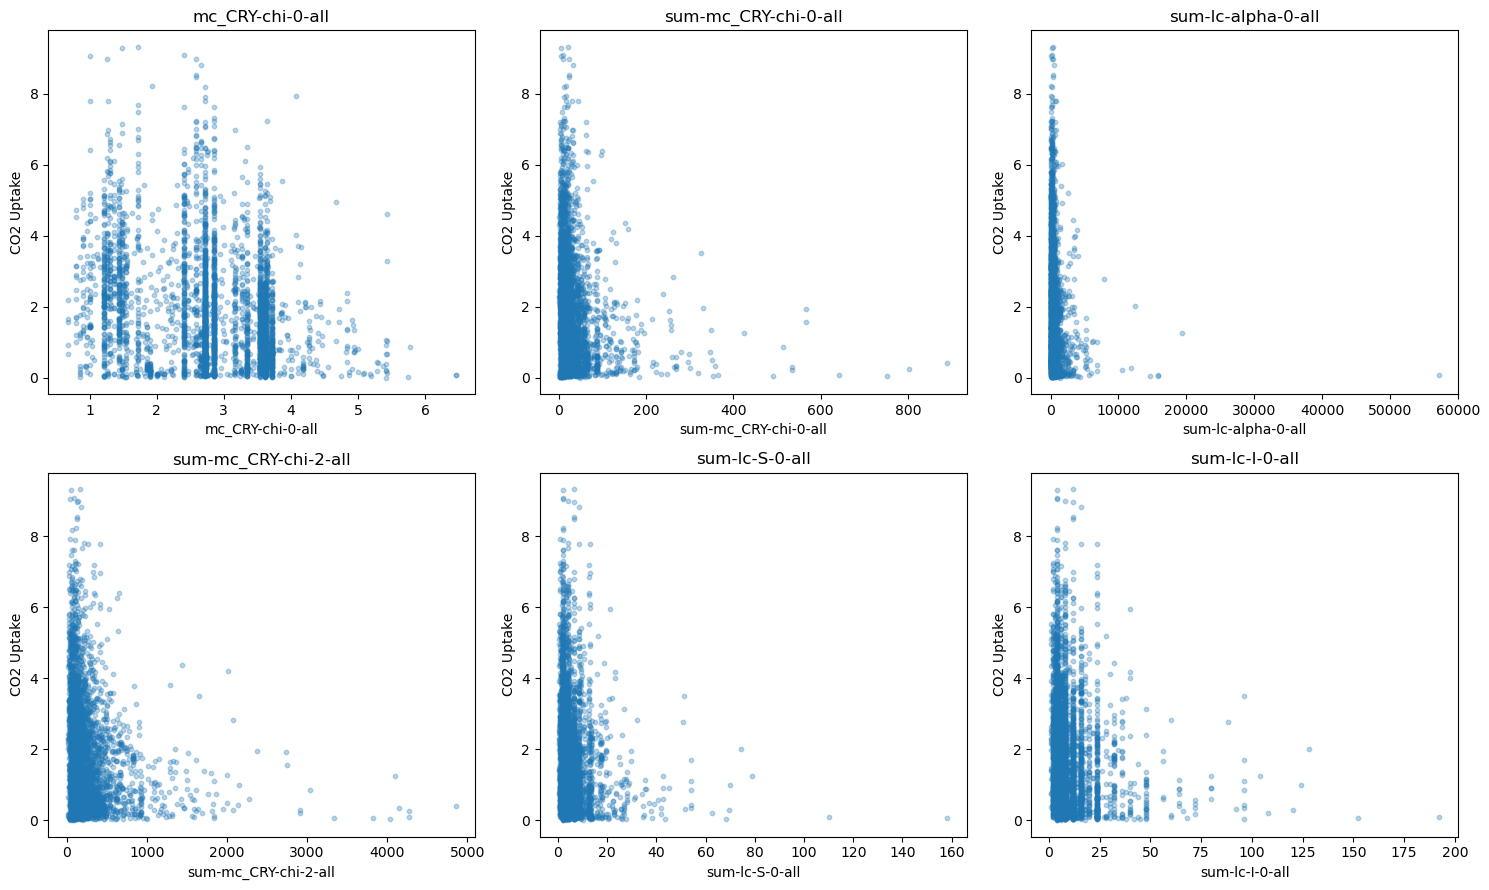

In [12]:
top_features = correlation_df["Feature"].head(6).tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flat, top_features):

    ax.scatter(
        X_train[feature],
        y_train,
        alpha=0.3,
        s=10
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("CO2 Uptake")
    ax.set_title(feature)

plt.tight_layout()
plt.show()

,Feature,Importance
14,mc_CRY-chi-0-all,0.026914
22,mc_CRY-I-1-all,0.026405
194,sum-lc-alpha-0-all,0.023375
16,mc_CRY-chi-2-all,0.022687
25,mc_CRY-T-0-all,0.018981
190,sum-lc-S-0-all,0.017209
30,mc_CRY-S-1-all,0.016367
12,total_POV_volumetric,0.014570
29,mc_CRY-S-0-all,0.013385
160,f-lig-Z-2,0.012885


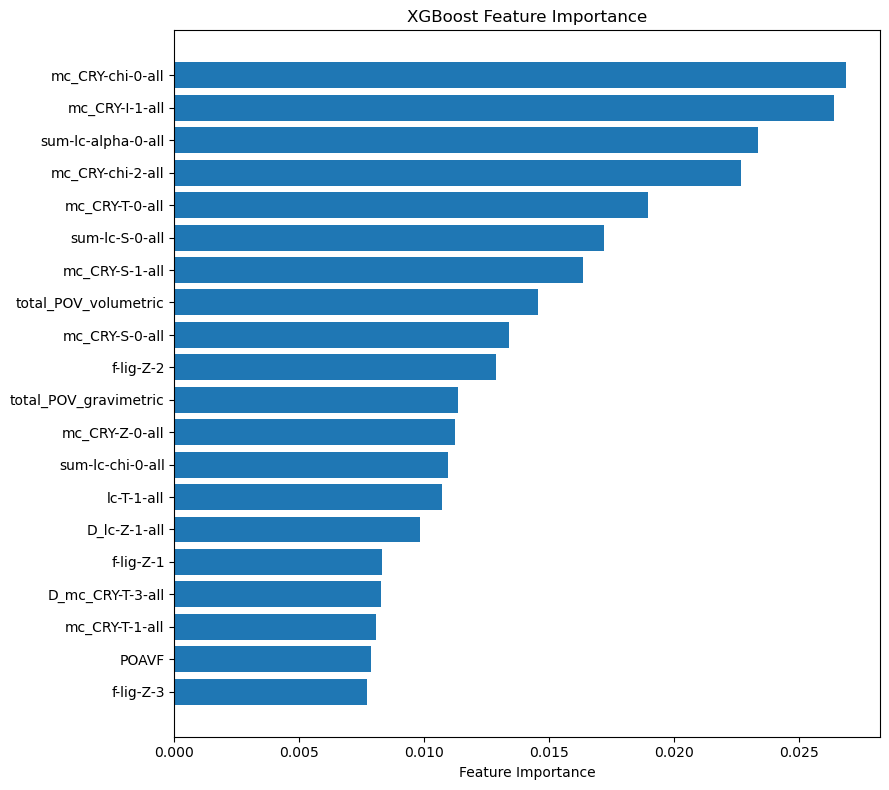

In [13]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_xgb.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(30))

plt.figure(figsize=(9, 8))

top20 = importance_df.head(20).sort_values("Importance")

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()

In [14]:
# Geometry descriptors: columns before the RAC blocks
geometry_cols = [
    col for col in X_train.columns
    if col in [
        "Df", "Di", "Dif",
        "POAVF",
        "POAV _cm^3/g_",
        "total_POV_volumetric",
        "total_POV_gravimetric"
    ]
    or col.startswith(("ASA", "NASA", "AV", "NAV"))
]

# All other descriptors
chemistry_cols = [
    col for col in X_train.columns
    if col not in geometry_cols
]

feature_groups = {
    "Geometry": geometry_cols,
    "Other Descriptors": chemistry_cols,
    "All Features": X_train.columns.tolist()
}

for name, cols in feature_groups.items():
    print(name, len(cols))

Geometry 9
Other Descriptors 263
All Features 272


In [16]:
print("Geometry features:")
print(geometry_cols)

print("\nOther descriptors:")
print(chemistry_cols)

Geometry features:
['ASA _m^2/cm^3_', 'Df', 'Di', 'Dif', 'NASA _m^2/cm^3_', 'POAV _cm^3/g_', 'POAVF', 'total_POV_volumetric', 'total_POV_gravimetric']

Other descriptors:
['PONAV _cm^3/g_', 'PONAVF', 'density _g/cm^3_', 'total_SA_volumetric', 'total_SA_gravimetric', 'mc_CRY-chi-0-all', 'mc_CRY-chi-1-all', 'mc_CRY-chi-2-all', 'mc_CRY-chi-3-all', 'mc_CRY-Z-0-all', 'mc_CRY-Z-1-all', 'mc_CRY-Z-2-all', 'mc_CRY-Z-3-all', 'mc_CRY-I-1-all', 'mc_CRY-I-2-all', 'mc_CRY-I-3-all', 'mc_CRY-T-0-all', 'mc_CRY-T-1-all', 'mc_CRY-T-2-all', 'mc_CRY-T-3-all', 'mc_CRY-S-0-all', 'mc_CRY-S-1-all', 'mc_CRY-S-2-all', 'mc_CRY-S-3-all', 'D_mc_CRY-chi-1-all', 'D_mc_CRY-chi-2-all', 'D_mc_CRY-chi-3-all', 'D_mc_CRY-Z-1-all', 'D_mc_CRY-Z-2-all', 'D_mc_CRY-Z-3-all', 'D_mc_CRY-T-1-all', 'D_mc_CRY-T-2-all', 'D_mc_CRY-T-3-all', 'D_mc_CRY-S-1-all', 'D_mc_CRY-S-2-all', 'D_mc_CRY-S-3-all', 'sum-mc_CRY-chi-0-all', 'sum-mc_CRY-chi-1-all', 'sum-mc_CRY-chi-2-all', 'sum-mc_CRY-chi-3-all', 'sum-mc_CRY-Z-0-all', 'sum-mc_CRY-Z-1-all

In [17]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

results = []

for name, cols in feature_groups.items():

    model = clone(best_xgb)

    scores = cross_validate(
        model,
        X_train[cols],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Feature Group": name,
        "Features": len(cols),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

ablation_results = pd.DataFrame(results)

display(ablation_results.sort_values("CV MAE"))

,Feature Group,Features,CV MAE,CV RMSE,CV R2
2,All Features,272,0.584895,0.883394,0.669145
1,Other Descriptors,263,0.629595,0.926758,0.635943
0,Geometry,9,1.008657,1.389405,0.179812


In [15]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

results = []

for name, cols in feature_groups.items():

    if not cols:
        continue

    model = clone(best_xgb)

    scores = cross_validate(
        model,
        X_train[cols],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    results.append({
        "Feature Group": name,
        "Features": len(cols),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

ablation_results = pd.DataFrame(results)

display(ablation_results.sort_values("CV MAE"))

,Feature Group,Features,CV MAE,CV R2
2,All Features,272,0.584895,0.669145
1,Other Descriptors,263,0.629595,0.635943
0,Geometry,9,1.008657,0.179812


In [18]:
geometry_cols = [
    "ASA _m^2/cm^3_",
    "Df",
    "Di",
    "Dif",
    "NASA _m^2/cm^3_",
    "POAV _cm^3/g_",
    "POAVF",
    "PONAV _cm^3/g_",
    "PONAVF",
    "density _g/cm^3_",
    "total_POV_volumetric",
    "total_POV_gravimetric",
    "total_SA_volumetric",
    "total_SA_gravimetric"
]

# Verify all geometry columns exist
assert all(col in X_train.columns for col in geometry_cols)

# Remaining RAC descriptors
rac_cols = [
    col for col in X_train.columns
    if col not in geometry_cols
]

# Update feature groups
feature_groups = {
    "Geometry (14)": geometry_cols,
    "RAC (258)": rac_cols,
    "All Features (272)": X_train.columns.tolist()
}

for name, cols in feature_groups.items():
    print(name, len(cols))
    

Geometry (14) 14
RAC (258) 258
All Features (272) 272


In [19]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

results = []

for name, cols in feature_groups.items():

    model = clone(best_xgb)

    scores = cross_validate(
        model,
        X_train[cols],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        },
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Feature Group": name,
        "Features": len(cols),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

ablation_results = pd.DataFrame(results)

display(ablation_results.sort_values("CV MAE"))

,Feature Group,Features,CV MAE,CV R2
2,All Features (272),272,0.584895,0.669145
1,RAC (258),258,0.691008,0.575053
0,Geometry (14),14,0.989408,0.206442


In [20]:
# Group RAC descriptors by structural origin

rac_groups = {
    "Metal Center": [],
    "Linker": [],
    "Functional Group": [],
    "Ligand": []
}

for col in rac_cols:

    if "mc_CRY" in col:
        rac_groups["Metal Center"].append(col)

    elif "lc-" in col or "lc_" in col:
        rac_groups["Linker"].append(col)

    elif "func-" in col or "func_" in col:
        rac_groups["Functional Group"].append(col)

    elif "f-lig-" in col:
        rac_groups["Ligand"].append(col)

# Check whether all RAC descriptors are assigned
assigned = set(
    col
    for cols in rac_groups.values()
    for col in cols
)

unassigned = set(rac_cols) - assigned

for name, cols in rac_groups.items():
    print(name, len(cols))

print("Unassigned:", len(unassigned))
print(sorted(unassigned))

Metal Center 63
Linker 77
Functional Group 78
Ligand 40
Unassigned: 0
[]


In [21]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

# Define feature combinations
feature_groups_ablation = {
    "Geometry": geometry_cols,

    "Geometry + Metal Center":
        geometry_cols + rac_groups["Metal Center"],

    "Geometry + Linker":
        geometry_cols + rac_groups["Linker"],

    "Geometry + Functional Group":
        geometry_cols + rac_groups["Functional Group"],

    "Geometry + Ligand":
        geometry_cols + rac_groups["Ligand"],

    "All Features":
        X_train.columns.tolist()
}

results = []

for name, cols in feature_groups_ablation.items():

    model = clone(best_xgb)

    scores = cross_validate(
        model,
        X_train[cols],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Feature Group": name,
        "Features": len(cols),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

ablation_results = pd.DataFrame(results)

display(
    ablation_results.sort_values("CV MAE")
)

,Feature Group,Features,CV MAE,CV RMSE,CV R2
5,All Features,272,0.584895,0.883394,0.669145
1,Geometry + Metal Center,77,0.610065,0.907436,0.650605
4,Geometry + Ligand,54,0.810403,1.172361,0.416412
2,Geometry + Linker,91,0.812901,1.184863,0.404804
3,Geometry + Functional Group,92,0.893733,1.256991,0.328366
0,Geometry,14,0.989408,1.366242,0.206442


In [22]:
results_removal = []

for group_name, group_cols in rac_groups.items():

    remaining_cols = [
        col for col in X_train.columns
        if col not in group_cols
    ]

    model = clone(best_xgb)

    scores = cross_validate(
        model,
        X_train[remaining_cols],
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
        error_score="raise"
    )

    results_removal.append({
        "Removed Group": group_name,
        "Remaining Features": len(remaining_cols),
        "CV MAE": -scores["test_score"].mean()
    })

removal_df = pd.DataFrame(results_removal)

removal_df["MAE Increase"] = (
    removal_df["CV MAE"] - 0.584895
)

display(
    removal_df.sort_values(
        "MAE Increase",
        ascending=False
    )
)

,Removed Group,Remaining Features,CV MAE,MAE Increase
0,Metal Center,209,0.779620,0.194725
3,Ligand,232,0.595953,0.011058
2,Functional Group,194,0.589132,0.004237
1,Linker,195,0.583697,-0.001198


In [23]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

base_cols = geometry_cols + rac_groups["Metal Center"]

feature_combinations = {
    "Geometry + Metal Center": base_cols,

    "+ Linker":
        base_cols + rac_groups["Linker"],

    "+ Functional Group":
        base_cols + rac_groups["Functional Group"],

    "+ Ligand":
        base_cols + rac_groups["Ligand"],

    "All Features":
        X_train.columns.tolist()
}

results = []

for name, cols in feature_combinations.items():

    model = clone(best_xgb)

    scores = cross_validate(
        model,
        X_train[cols],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        },
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Feature Group": name,
        "Features": len(cols),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("CV MAE"))

,Feature Group,Features,CV MAE,CV R2
3,+ Ligand,117,0.579368,0.681988
4,All Features,272,0.584895,0.669145
1,+ Linker,154,0.600358,0.661215
2,+ Functional Group,155,0.601187,0.659489
0,Geometry + Metal Center,77,0.610065,0.650605


In [24]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

feature_sets = {
    "Full (272)": X_train.columns.tolist(),

    "Without Linker (195)": [
        col for col in X_train.columns
        if col not in rac_groups["Linker"]
    ],

    "Geometry + Metal (77)":
        geometry_cols + rac_groups["Metal Center"]
}

results = []
fold_maes = {}

for name, cols in feature_sets.items():

    scores = cross_validate(
        clone(best_xgb),
        X_train[cols],
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    train_mae = -scores["train_score"]
    cv_mae = -scores["test_score"]

    results.append({
        "Model": name,
        "Features": len(cols),
        "Train MAE": train_mae.mean(),
        "CV MAE": cv_mae.mean(),
        "CV MAE Std": cv_mae.std(),
        "Train-CV Gap": cv_mae.mean() - train_mae.mean()
    })

    fold_maes[name] = cv_mae

comparison_df = pd.DataFrame(results)

display(comparison_df.sort_values("CV MAE"))

print("\nMAE for each fold:")
display(pd.DataFrame(fold_maes))

,Model,Features,Train MAE,CV MAE,CV MAE Std,Train-CV Gap
1,Without Linker (195),195,0.101287,0.583697,0.031624,0.482410
0,Full (272),272,0.097481,0.584895,0.032860,0.487414
2,Geometry + Metal (77),77,0.135443,0.610065,0.034525,0.474622



MAE for each fold:


,Full (272),Without Linker (195),Geometry + Metal (77)
0,0.577086,0.571581,0.578494
1,0.604406,0.592796,0.628196
2,0.529249,0.531890,0.559667
3,0.585712,0.594026,0.636660
4,0.628024,0.628194,0.647309


In [25]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

selected_cols = (
    geometry_cols
    + rac_groups["Metal Center"]
    + rac_groups["Ligand"]
)

full_cols = X_train.columns.tolist()

feature_sets = {
    "Selected (117)": selected_cols,
    "Full (272)": full_cols
}

fold_results = {}

for name, cols in feature_sets.items():

    scores = cross_validate(
        clone(best_xgb),
        X_train[cols],
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    fold_results[name] = {
        "Train MAE": -scores["train_score"],
        "CV MAE": -scores["test_score"]
    }

comparison = pd.DataFrame({
    "Selected CV MAE": fold_results["Selected (117)"]["CV MAE"],
    "Full CV MAE": fold_results["Full (272)"]["CV MAE"]
})

comparison["Improvement"] = (
    comparison["Full CV MAE"]
    - comparison["Selected CV MAE"]
)

display(comparison)

print("\nMean improvement:", comparison["Improvement"].mean())
print("Std improvement:", comparison["Improvement"].std())
print("Folds improved:", (comparison["Improvement"] > 0).sum(), "/ 5")

,Selected CV MAE,Full CV MAE,Improvement
0,0.563631,0.577086,0.013454
1,0.596413,0.604406,0.007993
2,0.513863,0.529249,0.015386
3,0.600855,0.585712,-0.015142
4,0.622079,0.628024,0.005945



Mean improvement: 0.0055271359252049065
Std improvement: 0.012181127161933508
Folds improved: 4 / 5


In [26]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
import numpy as np
import pandas as pd

selected_cols = (
    geometry_cols
    + rac_groups["Metal Center"]
    + rac_groups["Ligand"]
)

pred_selected = cross_val_predict(
    clone(best_xgb),
    X_train[selected_cols],
    y_train,
    cv=cv,
    n_jobs=1
)

pred_full = cross_val_predict(
    clone(best_xgb),
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

error_comparison = pd.DataFrame({
    "Actual": np.asarray(y_train),
    "Selected_Error": np.abs(
        np.asarray(y_train) - pred_selected
    ),
    "Full_Error": np.abs(
        np.asarray(y_train) - pred_full
    ),
    "Selected_Residual": np.asarray(y_train) - pred_selected,
    "Full_Residual": np.asarray(y_train) - pred_full
})

bins = [-np.inf, 1, 2, 3, 4, 5, np.inf]

error_comparison["Uptake_Range"] = pd.cut(
    error_comparison["Actual"],
    bins=bins,
    labels=["<1", "1–2", "2–3", "3–4", "4–5", "≥5"]
)

summary = error_comparison.groupby(
    "Uptake_Range",
    observed=True
).agg(
    Count=("Actual", "size"),
    Selected_MAE=("Selected_Error", "mean"),
    Full_MAE=("Full_Error", "mean"),
    Selected_Bias=("Selected_Residual", "mean"),
    Full_Bias=("Full_Residual", "mean")
)

display(summary)

,Count,Selected_MAE,Full_MAE,Selected_Bias,Full_Bias
Uptake_Range,,,,,
<1,1595,0.470442,0.493212,-0.400007,-0.425354
1–2,984,0.456960,0.441606,-0.164319,-0.166373
2–3,665,0.501920,0.496346,0.217466,0.219245
3–4,390,0.757833,0.739206,0.527579,0.555860
4–5,193,1.046695,1.055987,0.889548,0.921088
≥5,184,1.589585,1.644726,1.545476,1.593843


Spearman (Distance vs Error): 0.2773278380012671


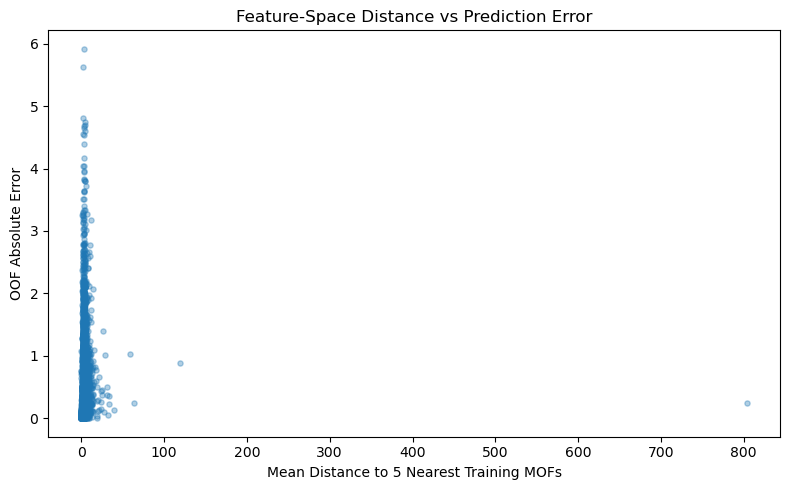

In [27]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import KFold

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_cols = (
    geometry_cols
    + rac_groups["Metal Center"]
    + rac_groups["Ligand"]
)

X_selected = X_train[selected_cols]
y_array = y_train.to_numpy()

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_distance = np.zeros(len(X_selected))

for train_idx, val_idx in cv.split(X_selected):

    X_fold_train = X_selected.iloc[train_idx]
    X_fold_val = X_selected.iloc[val_idx]

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_tr_imp = imputer.fit_transform(X_fold_train)
    X_va_imp = imputer.transform(X_fold_val)

    X_tr_scaled = scaler.fit_transform(X_tr_imp)
    X_va_scaled = scaler.transform(X_va_imp)

    nn = NearestNeighbors(n_neighbors=5)
    nn.fit(X_tr_scaled)

    distances, _ = nn.kneighbors(X_va_scaled)

    oof_distance[val_idx] = distances.mean(axis=1)

# Use previous OOF predictions
absolute_error = np.abs(y_array - pred_selected)

print(
    "Spearman (Distance vs Error):",
    pd.Series(oof_distance).corr(
        pd.Series(absolute_error),
        method="spearman"
    )
)

plt.figure(figsize=(8, 5))

plt.scatter(
    oof_distance,
    absolute_error,
    alpha=0.35,
    s=14
)

plt.xlabel("Mean Distance to 5 Nearest Training MOFs")
plt.ylabel("OOF Absolute Error")
plt.title("Feature-Space Distance vs Prediction Error")

plt.tight_layout()
plt.show()

In [28]:
coverage_df = pd.DataFrame({
    "Actual": y_array,
    "NN_Distance": oof_distance,
    "Absolute_Error": absolute_error
})

coverage_df["Uptake_Range"] = pd.cut(
    coverage_df["Actual"],
    bins=[-np.inf, 1, 2, 3, 4, 5, np.inf],
    labels=["<1", "1–2", "2–3", "3–4", "4–5", "≥5"]
)

coverage_summary = coverage_df.groupby(
    "Uptake_Range",
    observed=True
).agg(
    Count=("Actual", "size"),
    Mean_NN_Distance=("NN_Distance", "mean"),
    Median_NN_Distance=("NN_Distance", "median"),
    MAE=("Absolute_Error", "mean")
)

display(coverage_summary)

,Count,Mean_NN_Distance,Median_NN_Distance,MAE
Uptake_Range,,,,
<1,1595,3.997374,2.740517,0.470442
1–2,984,3.208131,2.694457,0.456960
2–3,665,3.260560,2.747492,0.501920
3–4,390,2.992856,2.663143,0.757833
4–5,193,2.777050,2.353940,1.046695
≥5,184,2.399888,2.419139,1.589585


In [30]:
from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

import numpy as np
import pandas as pd

X_selected = X_train[selected_cols]
y_array = y_train.to_numpy()

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

nearest_distance = np.zeros(len(X_selected))
nearest_uptake_diff = np.zeros(len(X_selected))
nearest_neighbor_uptake = np.zeros(len(X_selected))

for train_idx, val_idx in cv.split(X_selected):

    X_fold_train = X_selected.iloc[train_idx]
    X_fold_val = X_selected.iloc[val_idx]

    y_fold_train = y_array[train_idx]
    y_fold_val = y_array[val_idx]

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_tr_scaled = scaler.fit_transform(
        imputer.fit_transform(X_fold_train)
    )

    X_val_scaled = scaler.transform(
        imputer.transform(X_fold_val)
    )

    nn = NearestNeighbors(n_neighbors=1)
    nn.fit(X_tr_scaled)

    distances, neighbors = nn.kneighbors(X_val_scaled)

    neighbor_y = y_fold_train[neighbors[:, 0]]

    nearest_distance[val_idx] = distances[:, 0]
    nearest_neighbor_uptake[val_idx] = neighbor_y

    nearest_uptake_diff[val_idx] = np.abs(
        y_fold_val - neighbor_y
    )

neighbor_df = pd.DataFrame({
    "Actual": y_array,
    "NN_Distance": nearest_distance,
    "Neighbor_Uptake": nearest_neighbor_uptake,
    "Uptake_Difference": nearest_uptake_diff
})

neighbor_df["Uptake_Range"] = pd.cut(
    neighbor_df["Actual"],
    bins=[-np.inf, 1, 2, 3, 4, 5, np.inf],
    labels=["<1", "1–2", "2–3", "3–4", "4–5", "≥5"]
)

neighbor_summary = neighbor_df.groupby(
    "Uptake_Range",
    observed=True
).agg(
    Count=("Actual", "size"),
    Mean_NN_Distance=("NN_Distance", "mean"),
    Mean_Uptake_Difference=("Uptake_Difference", "mean"),
    Median_Uptake_Difference=("Uptake_Difference", "median")
)

display(neighbor_summary)

,Count,Mean_NN_Distance,Mean_Uptake_Difference,Median_Uptake_Difference
Uptake_Range,,,,
<1,1595,2.982629,0.570368,0.147430
1–2,984,2.323686,0.739161,0.449944
2–3,665,2.391543,0.826358,0.595415
3–4,390,2.229792,1.200757,1.034862
4–5,193,2.044205,1.506544,1.147149
≥5,184,1.665897,2.005012,1.427970


In [31]:
neighbor_summary2 = neighbor_df.groupby(
    "Uptake_Range",
    observed=True
).agg(
    Count=("Actual", "size"),
    Mean_Actual=("Actual", "mean"),
    Mean_Neighbor_Uptake=("Neighbor_Uptake", "mean"),
    Mean_Distance=("NN_Distance", "mean"),
    Mean_Absolute_Difference=("Uptake_Difference", "mean")
)

neighbor_summary2["Neighbor_Bias"] = (
    neighbor_summary2["Mean_Actual"]
    - neighbor_summary2["Mean_Neighbor_Uptake"]
)

display(neighbor_summary2)

,Count,Mean_Actual,Mean_Neighbor_Uptake,Mean_Distance,Mean_Absolute_Difference,Neighbor_Bias
Uptake_Range,,,,,,
<1,1595,0.481790,0.959163,2.982629,0.570368,-0.477372
1–2,984,1.474320,1.734981,2.323686,0.739161,-0.260660
2–3,665,2.438543,2.169728,2.391543,0.826358,0.268816
3–4,390,3.442263,2.720258,2.229792,1.200757,0.722004
4–5,193,4.474286,3.501065,2.044205,1.506544,0.973221
≥5,184,6.117178,4.506331,1.665897,2.005012,1.610847


In [32]:
from sklearn.model_selection import KFold
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

random_diff = np.zeros(len(y_train))
y_array = y_train.to_numpy()

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for tr_idx, va_idx in cv.split(X_train):
    random_neighbors = rng.choice(
        tr_idx,
        size=len(va_idx),
        replace=True
    )

    random_diff[va_idx] = np.abs(
        y_array[va_idx] - y_array[random_neighbors]
    )

neighbor_df["Random_Difference"] = random_diff

summary = neighbor_df.groupby(
    "Uptake_Range",
    observed=True
).agg(
    NN_Difference=("Uptake_Difference", "mean"),
    Random_Difference=("Random_Difference", "mean")
)

summary["Improvement"] = (
    summary["Random_Difference"]
    - summary["NN_Difference"]
)

display(summary)

,NN_Difference,Random_Difference,Improvement
Uptake_Range,,,
<1,0.570368,1.401908,0.831540
1–2,0.739161,1.212839,0.473678
2–3,0.826358,1.415543,0.589185
3–4,1.200757,2.098292,0.897535
4–5,1.506544,2.841522,1.334978
≥5,2.005012,4.425765,2.420753


In [33]:
duplicate_mask = X.duplicated(keep=False)

print(
    "Duplicate feature vectors:",
    duplicate_mask.sum()
)

if duplicate_mask.any():

    duplicates = pd.DataFrame({
        "MOFname": train.loc[duplicate_mask, "MOFname"],
        "CO2_Uptake": y.loc[duplicate_mask]
    })

    display(duplicates.head(20))

Duplicate feature vectors: 28


,MOFname,CO2_Uptake
416,FECXUI_clean,1.364014
417,MISQIQ_clean,2.459038
418,QOMFEE_clean,1.130768
419,JENKIX_SL,0.537006
420,VAZTUM_clean,0.226272
421,GIKMOD01_clean,0.911650
422,BEFMAC_clean,6.469821
423,WODFOL_clean,1.722424
424,OKUTEV_clean,0.223218
425,FABCUI_clean,1.359029


In [34]:
# Group by all 272 input features
duplicate_groups = (
    train.assign(
        _target=train[TARGET]
    )
    .groupby(feature_cols, dropna=False)
    .agg(
        Count=("_target", "size"),
        Target_Unique=("_target", "nunique"),
        Target_Min=("_target", "min"),
        Target_Max=("_target", "max")
    )
)

duplicate_groups = duplicate_groups[
    duplicate_groups["Count"] > 1
]

print("Duplicate groups:", len(duplicate_groups))

print(
    "Groups with different target values:",
    (duplicate_groups["Target_Unique"] > 1).sum()
)

display(duplicate_groups[
    ["Count", "Target_Unique", "Target_Min", "Target_Max"]
])

Duplicate groups: 14
Groups with different target values: 0


Count  \
ASA [m^2/cm^3] Df       Di       Dif      NASA [m^2/cm^3] POAV [cm^3/g] POAVF   PONAV [cm^3/g] PONAVF  density [g/cm^3] total_SA_volumetric total_SA_gravimetric total_POV_volumetric total_POV_gravimetric mc_CRY-chi-0-all mc_CRY-chi-1-all mc_CRY-chi-2-all mc_CRY-chi-3-all mc_CRY-Z-0-all mc_CRY-Z-1-all mc_CRY-Z-2-all mc_CRY-Z-3-all mc_CRY-I-1-all mc_CRY-I-2-all mc_CRY-I-3-all mc_CRY-T-0-all mc_CRY-T-1-all mc_CRY-T-2-all mc_CRY-T-3-all mc_CRY-S-0-all mc_CRY-S-1-all mc_CRY-S-2-all mc_CRY-S-3-all D_mc_CRY-chi-1-all D_mc_CRY-chi-2-all D_mc_CRY-chi-3-all D_mc_CRY-Z-1-all D_mc_CRY-Z-2-all D_mc_CRY-Z-3-all D_mc_CRY-T-1-all D_mc_CRY-T-2-all D_mc_CRY-T-3-all D_mc_CRY-S-1-all D_mc_CRY-S-2-all D_mc_CRY-S-3-all sum-mc_CRY-chi-0-all sum-mc_CRY-chi-1-all sum-mc_CRY-chi-2-all sum-mc_CRY-chi-3-all sum-mc_CRY-Z-0-all sum-mc_CRY-Z-1-all sum-mc_CRY-Z-2-all sum-mc_CRY-Z-3-all sum-mc_CRY-I-0-all sum-mc_CRY-I-1-all sum-mc_CRY-I-2-all sum-mc_CRY-I-3-all sum-mc_CRY-T-0-all sum-mc_CRY-T-1-all sum-mc_CRY-T-2-all sum-mc_CRY-T-3-all sum-mc_CRY-S-0-all sum-mc_CRY-S-1-all sum-mc_CRY-S-2-all sum-mc_CRY-S-3-all sum-D_mc_CRY-chi-1-all sum-D_mc_CRY-chi-2-all sum-D_mc_CRY-chi-3-all sum-D_mc_CRY-Z-1-all sum-D_mc_CRY-Z-2-all sum-D_mc_CRY-Z-3-all sum-D_mc_CRY-T-1-all sum-D_mc_CRY-T-2-all sum-D_mc_CRY-T-3-all sum-D_mc_CRY-S-1-all sum-D_mc_CRY-S-2-all sum-D_mc_CRY-S-3-all lc-chi-0-all lc-chi-1-all lc-chi-2-all lc-chi-3-all lc-Z-0-all lc-Z-1-all lc-Z-2-all lc-Z-3-all lc-I-1-all lc-I-2-all lc-I-3-all lc-T-0-all lc-T-1-all lc-T-2-all lc-T-3-all lc-S-0-all lc-S-1-all lc-S-2-all lc-S-3-all lc-alpha-0-all lc-alpha-1-all lc-alpha-2-all lc-alpha-3-all D_lc-chi-1-all D_lc-chi-2-all D_lc-chi-3-all D_lc-Z-1-all D_lc-Z-2-all D_lc-Z-3-all D_lc-T-1-all D_lc-T-2-all D_lc-T-3-all D_lc-S-1-all D_lc-S-2-all D_lc-S-3-all D_lc-alpha-1-all D_lc-alpha-2-all D_lc-alpha-3-all func-chi-0-all func-chi-1-all func-chi-2-all func-chi-3-all func-Z-0-all func-Z-1-all func-Z-2-all func-Z-3-all func-I-0-all func-I-1-all func-I-2-all func-I-3-all func-T-0-all func-T-1-all func-T-2-all func-T-3-all func-S-0-all func-S-1-all func-S-2-all func-S-3-all func-alpha-0-all func-alpha-1-all func-alpha-2-all func-alpha-3-all D_func-chi-1-all D_func-chi-2-all D_func-chi-3-all D_func-Z-1-all D_func-Z-2-all D_func-Z-3-all D_func-T-1-all D_func-T-2-all D_func-T-3-all D_func-S-1-all D_func-S-2-all D_func-S-3-all D_func-alpha-1-all D_func-alpha-2-all D_func-alpha-3-all f-lig-chi-0 f-lig-chi-1 f-lig-chi-2 f-lig-chi-3 f-lig-Z-0   f-lig-Z-1   f-lig-Z-2   f-lig-Z-3   f-lig-I-0 f-lig-I-1  f-lig-I-2  f-lig-I-3  f-lig-T-0  f-lig-T-1   f-lig-T-2   f-lig-T-3   f-lig-S-0 f-lig-S-1 f-lig-S-2  f-lig-S-3  sum-lc-chi-0-all sum-lc-chi-1-all sum-lc-chi-2-all sum-lc-chi-3-all sum-lc-Z-0-all sum-lc-Z-1-all sum-lc-Z-2-all sum-lc-Z-3-all sum-lc-I-0-all sum-lc-I-1-all sum-lc-I-2-all sum-lc-I-3-all sum-lc-T-0-all sum-lc-T-1-all sum-lc-T-2-all sum-lc-T-3-all sum-lc-S-0-all sum-lc-S-1-all sum-lc-S-2-all sum-lc-S-3-all sum-lc-alpha-0-all sum-lc-alpha-1-all sum-lc-alpha-2-all sum-lc-alpha-3-all sum-D_lc-chi-1-all sum-D_lc-chi-2-all sum-D_lc-chi-3-all sum-D_lc-Z-1-all sum-D_lc-Z-2-all sum-D_lc-Z-3-all sum-D_lc-T-1-all sum-D_lc-T-2-all sum-D_lc-T-3-all sum-D_lc-S-1-all sum-D_lc-S-2-all sum-D_lc-S-3-all sum-D_lc-alpha-1-all sum-D_lc-alpha-2-all sum-D_lc-alpha-3-all sum-func-chi-0-all sum-func-chi-1-all sum-func-chi-2-all sum-func-chi-3-all sum-func-Z-0-all sum-func-Z-1-all sum-func-Z-2-all sum-func-Z-3-all sum-func-I-0-all sum-func-I-1-all sum-func-I-2-all sum-func-I-3-all sum-func-T-0-all sum-func-T-1-all sum-func-T-2-all sum-func-T-3-all sum-func-S-0-all sum-func-S-1-all sum-func-S-2-all sum-func-S-3-all sum-func-alpha-0-all sum-func-alpha-1-all sum-func-alpha-2-all sum-func-alpha-3-all sum-D_func-chi-1-all sum-D_func-chi-2-all sum-D_func-chi-3-all sum-D_func-Z-1-all sum-D_func-Z-2-all sum-D_func-Z-3-all sum-D_func-T-1-all sum-D_func-T-2-all sum-D_func-T-3-all sum-D_func-S-1-all sum-D_func-S-2-all sum-D_func-S-3-all sum-D_func-alpha-1

In [35]:
print(
    "Exact duplicate rows:",
    train.duplicated().sum()
)

print(
    "Duplicate MOF names:",
    train["MOFname"].duplicated().sum()
)

print(
    "Duplicate feature rows:",
    X.duplicated().sum()
)

print(
    "Rows involved in feature duplicates:",
    X.duplicated(keep=False).sum()
)

Exact duplicate rows: 14
Duplicate MOF names: 14
Duplicate feature rows: 14
Rows involved in feature duplicates: 28


In [36]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

# Remove exact duplicate records
keep_mask = ~train.duplicated()

X_clean = X.loc[keep_mask].copy()
y_clean = y.loc[keep_mask].copy()

# Recreate 80/20 split
from sklearn.model_selection import train_test_split

X_train_clean, X_val_clean, y_train_clean, y_val_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    clone(best_xgb),
    X_train_clean,
    y_train_clean,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
    error_score="raise"
)

print("CV MAE after deduplication:",
      -scores["test_score"].mean())

CV MAE after deduplication: 0.5865341483845008


In [37]:
from sklearn.model_selection import train_test_split

X_train_clean, X_val_clean, y_train_clean, y_val_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train_clean.shape)
print("Validation:", X_val_clean.shape)

Training: (4000, 272)
Validation: (1000, 272)


In [38]:
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
import pandas as pd

selected_cols = (
    geometry_cols
    + rac_groups["Metal Center"]
    + rac_groups["Ligand"]
)

feature_sets = {
    "Selected (117)": selected_cols,
    "Full (272)": X_train_clean.columns.tolist()
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, cols in feature_sets.items():

    scores = cross_validate(
        clone(best_xgb),
        X_train_clean[cols],
        y_train_clean,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "Features": len(cols),
        "Train MAE": -scores["train_MAE"].mean(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

display(pd.DataFrame(results).sort_values("CV MAE"))

,Model,Features,Train MAE,CV MAE,CV RMSE,CV R2
1,Full (272),272,0.098883,0.586534,0.883012,0.670708
0,Selected (117),117,0.113220,0.593091,0.883028,0.670839


In [39]:
import xgboost as xgb
print(xgb.__version__)

3.2.0


In [40]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

objectives = [
    "reg:squarederror",
    "reg:absoluteerror",
    "reg:pseudohubererror"
]

results = []

for objective in objectives:

    model = clone(best_xgb)

    model.set_params(objective=objective)

    scores = cross_validate(
        model,
        X_train_clean,
        y_train_clean,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Objective": objective,
        "Train MAE": -scores["train_MAE"].mean(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

loss_results = pd.DataFrame(results)

display(loss_results.sort_values("CV MAE"))

,Objective,Train MAE,CV MAE,CV RMSE,CV R2
0,reg:squarederror,0.098883,0.586534,0.883012,0.670708
2,reg:pseudohubererror,0.124725,0.588327,0.885288,0.669503
1,reg:absoluteerror,0.326990,0.641715,0.971403,0.602441


In [41]:
import pandas as pd
import numpy as np

# pred_full must be OOF predictions from the full XGBoost model
residuals = y_train.to_numpy() - pred_full

residual_corr = pd.DataFrame({
    "Feature": X_train.columns,
    "Spearman": [
        pd.Series(X_train[col].to_numpy()).corr(
            pd.Series(residuals),
            method="spearman"
        )
        for col in X_train.columns
    ]
})

residual_corr["Abs Spearman"] = (
    residual_corr["Spearman"].abs()
)

display(
    residual_corr.sort_values(
        "Abs Spearman",
        ascending=False
    ).head(20)
)

,Feature,Spearman,Abs Spearman
145,D_func-T-1-all,-0.027837,0.027837
243,sum-D_func-T-1-all,-0.027531,0.027531
173,f-lig-S-3,0.026526,0.026526
169,f-lig-T-3,0.026427,0.026427
146,D_func-T-2-all,-0.026281,0.026281
172,f-lig-S-2,0.026168,0.026168
147,D_func-T-3-all,-0.025950,0.025950
233,sum-func-alpha-0-all,-0.025913,0.025913
160,f-lig-Z-2,0.025834,0.025834
168,f-lig-T-2,0.025604,0.025604


In [42]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_validate, KFold
import numpy as np

# Previously generated OOF predictions
residuals = y_train.to_numpy() - pred_full

residual_model = HistGradientBoostingRegressor(
    max_iter=200,
    max_leaf_nodes=15,
    learning_rate=0.05,
    l2_regularization=10,
    random_state=42
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    residual_model,
    X_train,
    residuals,
    cv=cv,
    scoring={
        "R2": "r2",
        "MAE": "neg_mean_absolute_error"
    },
    n_jobs=1
)

print("Residual Prediction CV R2:", scores["test_R2"].mean())
print("Residual Prediction CV MAE:", -scores["test_MAE"].mean())
print("Zero-residual baseline MAE:", np.mean(np.abs(residuals)))

Residual Prediction CV R2: -0.1846046987852787
Residual Prediction CV MAE: 0.6430232547740385
Zero-residual baseline MAE: 0.5848934924967343
